In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
work_folder = 'trivia'
saving_folder = 'prova'
results_folder = work_folder + '/' + saving_folder + '/results'
os.chdir(results_folder)

In [3]:
# load the results from the file
with open('results.txt', 'r') as f:
    results = f.readlines()
results = [line.split() for line in results]
results = np.array(results, dtype=float)

In [4]:
print(f'Best accumulated reward: {np.max(results[:,1])}')
print(f'Obtained in episode: {np.argmax(results[:,1])}')

Best accumulated reward: 1.1757171101786144
Obtained in episode: 0


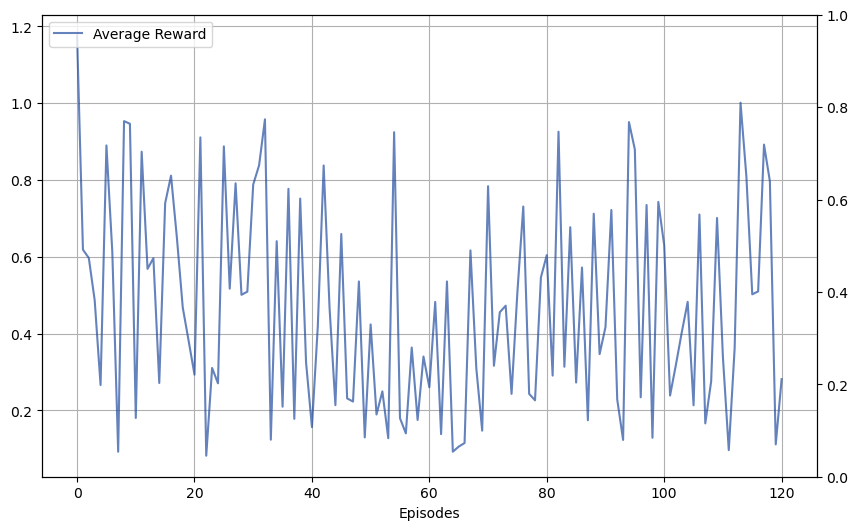

In [5]:
import matplotlib.cm as cm

init = 0
fin = -1

fig, ax1 = plt.subplots(figsize=(10,6))

cmap = cm.get_cmap('YlGnBu')
cmap1 = cm.get_cmap('YlOrRd')

std_a_c = cmap(0.3) 
a_color = cmap(0.4)

std_r_c = cmap(0.7)
rew_color = cmap(0.8)

std_op_c = cmap1(0.7)
op_color = cmap1(0.8)
ax2 = ax1.twinx()

ax1.plot(results[:,0][init:fin], results[:,1][init:fin], label='Average Reward', c=rew_color, alpha=0.7)
# ax1.plot(results[:,0][init:fin], results[:,2][init:fin], label='Avreage Order Parameter', c=op_color, alpha=0.7)
#ax2.plot(results[:,0][init:fin], results[:,2][init:fin]*100, label='Average action', c=a_color, alpha=0.7)

ax1.grid()
ax1.legend(loc='upper left')
#ax2.legend(loc='upper right')
#ax1.set_ylim(0,0.3)
ax1.set_xlabel('Episodes')
#ax2.tick_params(axis='y', labelcolor=cmap(0.5))
#ax2.set_ylabel(r'$\eta^{\prime}/\eta$', color=cmap(0.5))
#ax2.set_ylim(0, 200)
# plt.savefig('planner_learning.png')
plt.show()

/tmp/ipykernel_75188/1634602970.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[i].set_xticklabels(np.array(xticks * 10, dtype=int))
/tmp/ipykernel_75188/1634602970.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[i].set_xticklabels(np.array(xticks * 10, dtype=int))


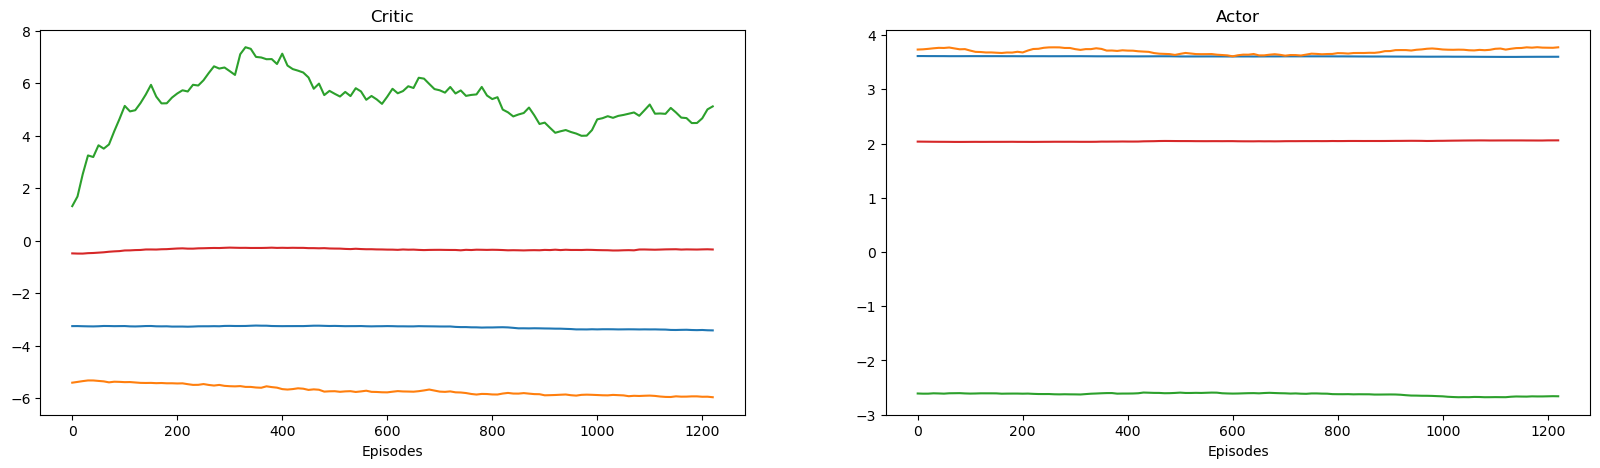

In [6]:
with open('critic_weights.txt', 'r') as f:
    c_weights = f.readlines()

with open('actor_weights.txt', 'r') as f:
    a_weights = f.readlines()

cw = [eval(line) for line in c_weights]
aw = [eval(line) for line in a_weights]

cwt = np.array(cw, dtype=float)
awt = np.array(aw, dtype=float)

fig, ax = plt.subplots(1, 2, figsize=(20, 5))

for i in range(2):
    
    if i==0:
        ax[i].plot(cwt)
        ax[i].set_title('Critic')
    else:
        ax[i].plot(awt)
        ax[i].set_title('Actor')

    ax[i].set_xlabel('Episodes')
    
    xticks = ax[i].get_xticks()  
    ax[i].set_xticklabels(np.array(xticks * 10, dtype=int))
plt.show()

In [7]:
#somma pesi layers
#normale
cwt[-1]

array([-3.4185395 , -5.966008  ,  5.119766  , -0.33476347])

In [8]:
# critic fermo
awt[-1]

array([ 3.601414 ,  3.775767 , -2.6614337,  2.059269 ])

ValueError: could not convert string to float: '[1.12466566]'

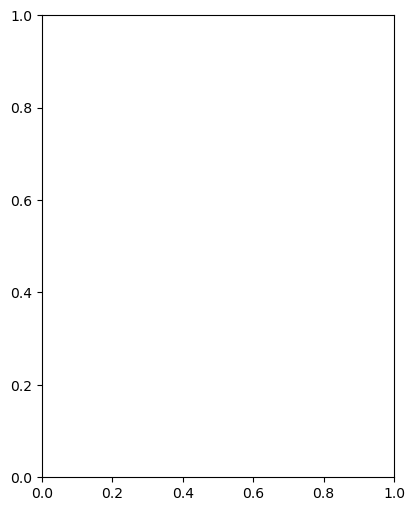

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm

updates = 50
coloramap = 'summer'

def plot_results(file, every=1):
    with open(file, 'r') as f:
        op = f.readlines()
    
    # Process data
    op = [line.split() for line in op]
    op = np.array(op, dtype=float)
    op = op.reshape(len(op)//updates, updates)
    
    # Use 'YlGnBu' colormap
    cmap = cm.get_cmap(coloramap)
    colors = cmap(np.linspace(0, 1, len(op)))

    # Plot each line with sequential colors
    for i in range(len(op)):
        if i % every == 0:
            plt.plot(op[i], color=colors[i])  # Use color from the colormap

# List of files to plot
files = ['reward.txt', '../results_test/reward.txt']

# Set up the layout for 2x2
plt.figure(figsize=(10, 6))

for idx, file in enumerate(files):
    plt.subplot(1, 2, idx + 1)  # Position plots in a 2x2 grid
    plot_results(file, every=1)  # Use the defined function
    if idx == 0:
        plt.title('Reward')
    elif idx == 1:
        plt.title('Test Reward')
    
    plt.xlabel('Time Step')
    plt.grid()

plt.show()